# Assignment 4
#### Paper: Certifying and removing disparate impact
#### Student ID: 2241420
#### Python version used: Python 3.11.9
#### note: full notebook took ~50s to run, mostly due to the Consistency calculation

1. Select three datasets to perform your analysis on. For example, you can use the Adult, German, and COMPAS datasets.

2. Compute the demographic parity difference (DP_Diff), the disparate impact ratio (DIR), and the consistency from the original labels of the dataset before mitigation and training any classifiers.

3. Perform a train/test split with stratification.

4. Follow the appropriate procedure for the selected method: pre-processing methods modify training data, in-processing methods are used during model training, and post-processing methods modify predictions after training.

5. On the held-out test data, report the demographic parity difference (DP_Diff), the disparate impact ratio (DIR), the consistency, and at least one predictive-performance measure from the final predictions after applying the complete mitigation pipeline.

6. Compare the values of the fairness measures before and after the bias mitigation.

## Loading libraries

A few packages might need to be installed, though they are pretty common and you are likely to already have them. 

`%pip install aif360 pandas numpy scikit-learn matplotlib`

In [1]:
#%pip install aif360 pandas numpy scikit-learn matplotlib BlackBoxAuditing


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

from aif360.algorithms.preprocessing import DisparateImpactRemover
from aif360.datasets import BinaryLabelDataset
from aif360.sklearn.metrics import (
    statistical_parity_difference,
    disparate_impact_ratio,
    consistency_score
)
from sklearn.linear_model import LogisticRegression

pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'
pip install 'aif360[OptimalTransport]'


## 1.1 Loading data
The 3 recommended datasets will be used. However, the 'German' dataset columns were unnamed, so I uploaded the names from Kaggle

In [2]:
adult = pd.read_csv("adult.csv")
german = pd.read_csv("german.data", sep=r"\s+", header=None)
compas = pd.read_csv("propublica_data_for_fairml.csv")

print("Adult:", adult.shape)
print("German Credit:", german.shape)
print("COMPAS:", compas.shape)

german.columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "people_liable",
    "telephone",
    "foreign_worker",
    "class"
]

Adult: (32561, 15)
German Credit: (1000, 21)
COMPAS: (6172, 12)


## 1.2 Protected variables, privileged groups, target variables
I will slightly rearrange the datasets before calculating the metrics so they are more convenient to work with. These are not yet the steps for bias mitigation. I do this so that all tables are categorised in the same way: the privileged group will have a value of 1, the unprivileged group - 0, and the positive and negative outcomes will be marked by 1 and 0 respectively. 


| Dataset | Protected variable | Privileged group | Unprivileged group | Target | Good outcome | Bad outcome |
|---|---|---|---|---|---|---|
| Adult | sex | Male | Female | `income` | 1 (>50K) | 0 (<=50K) |
| German | sex | Male  | Female | `class` | 1 (Good credit) | 0 (Bad credit) |
| COMPAS | race | Other races | African American | `Two_yr_Recidivism` | 1 (No recidivism) | 0 (Recidivism) |


#### 1.2.1 Adult
Just remapping the categoricals into binary for convenience. 

In [3]:
adult["sex"] = adult["sex"].map({"Male": 1, "Female": 0})
adult["income"] = adult["income"].map({">50K": 1, "<=50K": 0})

#### 1.2.2 German
There are multiple categories for both sexes, so I unify them and them map both variables to binaries as above. The original attribute `personal_status_sex` is removed. 

In [4]:
german["sex"] = german["personal_status_sex"].map({"A91": 1, "A92": 0, "A93": 1, "A94": 1, "A95": 0})
german["class"] = german["class"].map({1: 1, 2: 0})
german = german.drop(columns=["personal_status_sex"])


#### 1.2.3 Compas
Here, we need drop the original binary race columns to create a single column for race. The outcome variable is flipped so that 1 represents the favourable outcome and 0 the unfavourable just as in the other datasets. 

In [5]:
compas["race"] = 1 - compas["African_American"]
compas["Two_yr_Recidivism"] = 1 - compas["Two_yr_Recidivism"]
compas = compas.drop(columns=["African_American", "Asian", "Hispanic", "Native_American", "Other"])

## 2. Baseline measures

#### 2.1 DP_DIFF and DIR
I start with the first two metrics, as they can be calculated directly. 


In [6]:
adult_dpdiff = -statistical_parity_difference(
    adult["income"], prot_attr=adult["sex"], priv_group=1, pos_label=1)
adult_dir = disparate_impact_ratio(
    adult["income"], prot_attr=adult["sex"], priv_group=1, pos_label=1)

german_dpdiff = -statistical_parity_difference(
    german["class"], prot_attr=german["sex"], priv_group=1, pos_label=1)
german_dir = disparate_impact_ratio(
    german["class"], prot_attr=german["sex"], priv_group=1, pos_label=1)

compas_dpdiff = -statistical_parity_difference(
    compas["Two_yr_Recidivism"], prot_attr=compas["race"], priv_group=1, pos_label=1)
compas_dir = disparate_impact_ratio(
    compas["Two_yr_Recidivism"], prot_attr=compas["race"], priv_group=1, pos_label=1)

print("Adult:", adult_dpdiff, adult_dir)
print("German:", german_dpdiff, german_dir)
print("COMPAS:", compas_dpdiff, compas_dir)

Adult: 0.19627598779361352 0.3580225496813511
German: 0.07480130902290782 0.8965673282047968
COMPAS: 0.14009988991616285 0.7729154299195565


#### 2.2 Consistency
This one requires individual distance calculations, so we need to one-hot encode and scale the variables. 

In [7]:
def calculate_consistency(df, target):
    X = pd.get_dummies(df.drop(columns=[target]), dtype=int)
    X = MinMaxScaler().fit_transform(X)
    return consistency_score(X, df[target].to_numpy(), n_neighbors=5)


adult_consistency = calculate_consistency(adult, "income")
german_consistency = calculate_consistency(german, "class")
compas_consistency = calculate_consistency(compas, "Two_yr_Recidivism")

print("Adult:", adult_consistency)
print("German:", german_consistency)
print("COMPAS:", compas_consistency)

Adult: 0.8308405761493811
German: 0.7474000000000001
COMPAS: 0.6208684381075826


## 3. Train/test split with stratification
0.8 / 0.2 ratio is selected for splitting. 

In [8]:
adult_train, adult_test = train_test_split(
    adult,
    test_size=0.2,
    random_state=42,
    stratify=adult["income"]
)

german_train, german_test = train_test_split(
    german,
    test_size=0.2,
    random_state=42,
    stratify=german["class"]
)

compas_train, compas_test = train_test_split(
    compas,
    test_size=0.2,
    random_state=42,
    stratify=compas["Two_yr_Recidivism"]
)


## 4.1 Pre-processing the data before running the Disparate Impact Remover

Firstly, we need to identify the unordered nominal variables, as instructed by the paper. Compas are all integers, so we ignore it for now. For the others, we print out the non-numeric variables and make a judgmenet call on whether they are ordered or not. 

For adult, `education` is the only ordered categorical that needs to be restructured. The rest are unordered nominals and will be removed. 

In [9]:
for col in adult_train.select_dtypes(include="object").columns:
    print(f"\n{col}")
    for i, value in enumerate(sorted(adult_train[col].dropna().unique()), 1):
        print(f"  {i}. {value}")


workclass
  1. ?
  2. Federal-gov
  3. Local-gov
  4. Never-worked
  5. Private
  6. Self-emp-inc
  7. Self-emp-not-inc
  8. State-gov
  9. Without-pay

education
  1. 10th
  2. 11th
  3. 12th
  4. 1st-4th
  5. 5th-6th
  6. 7th-8th
  7. 9th
  8. Assoc-acdm
  9. Assoc-voc
  10. Bachelors
  11. Doctorate
  12. HS-grad
  13. Masters
  14. Preschool
  15. Prof-school
  16. Some-college

marital.status
  1. Divorced
  2. Married-AF-spouse
  3. Married-civ-spouse
  4. Married-spouse-absent
  5. Never-married
  6. Separated
  7. Widowed

occupation
  1. ?
  2. Adm-clerical
  3. Armed-Forces
  4. Craft-repair
  5. Exec-managerial
  6. Farming-fishing
  7. Handlers-cleaners
  8. Machine-op-inspct
  9. Other-service
  10. Priv-house-serv
  11. Prof-specialty
  12. Protective-serv
  13. Sales
  14. Tech-support
  15. Transport-moving

relationship
  1. Husband
  2. Not-in-family
  3. Other-relative
  4. Own-child
  5. Unmarried
  6. Wife

race
  1. Amer-Indian-Eskimo
  2. Asian-Pac-Islander
  3.

/var/folders/t_/v705sj4x1xx4r1027_stn6c00000gn/T/ipykernel_42855/2168568535.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in adult_train.select_dtypes(include="object").columns:


In [10]:
education_order = {
    "Preschool": 0,
    "1st-4th": 1,
    "5th-6th": 2,
    "7th-8th": 3,
    "9th": 4,
    "10th": 5,
    "11th": 6,
    "12th": 7,
    "HS-grad": 8,
    "Some-college": 9,
    "Assoc-acdm": 10,
    "Assoc-voc": 11,
    "Bachelors": 12,
    "Masters": 13,
    "Prof-school": 14,
    "Doctorate": 15
}

adult_train["education"] = adult_train["education"].map(education_order)
adult_test["education"] = adult_test["education"].map(education_order)

remove_columns = [
    "workclass", "marital.status", "occupation",
    "relationship", "race", "native.country"
]

adult_train.drop(columns=remove_columns, inplace=True)
adult_test.drop(columns=remove_columns, inplace=True)

For german dataset, visualisation here is not very intuitive as it is coded. So, I used the documentation (https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data) to make this decision. The majority of entries are unordered or the ordering is opaque, so only 3 variables are reordered and kept: `credit_history, savings, and employment duration`. 

In [11]:
credit_history_order = {
    "A30": 3,
    "A31": 3,
    "A32": 2,
    "A33": 1,
    "A34": 0
}

savings_order = {
    "A65": 0,
    "A61": 1,
    "A62": 2,
    "A63": 3,
    "A64": 4
}

employment_order = {
    "A71": 0,
    "A72": 1,
    "A73": 2,
    "A74": 3,
    "A75": 4
}

for df in [german_train, german_test]:
    df["credit_history"] = df["credit_history"].map(credit_history_order)
    df["savings"] = df["savings"].map(savings_order)
    df["employment"] = df["employment"].map(employment_order)
remove_columns = [
    "checking_account", "purpose", "other_debtors", "property",
    "other_installment_plans", "housing", "job", "telephone",
    "foreign_worker"
]

german_train.drop(columns=remove_columns, inplace=True)
german_test.drop(columns=remove_columns, inplace=True)

#### Then, the variables need to be scaled to 0-1 range. 

In [12]:
# Adult
adult_scaler = MinMaxScaler().fit(adult_train.drop(columns="income").astype(float))
adult_train[adult_train.drop(columns="income").columns] = adult_scaler.transform(adult_train.drop(columns="income").astype(float))
adult_test[adult_test.drop(columns="income").columns] = adult_scaler.transform(adult_test.drop(columns="income").astype(float))

# German
german_scaler = MinMaxScaler().fit(german_train.drop(columns="class").astype(float))
german_train[german_train.drop(columns="class").columns] = german_scaler.transform(german_train.drop(columns="class").astype(float))
german_test[german_test.drop(columns="class").columns] = german_scaler.transform(german_test.drop(columns="class").astype(float))

# COMPAS
compas_scaler = MinMaxScaler().fit(compas_train.drop(columns="Two_yr_Recidivism").astype(float))
compas_train[compas_train.drop(columns="Two_yr_Recidivism").columns] = compas_scaler.transform(compas_train.drop(columns="Two_yr_Recidivism").astype(float))
compas_test[compas_test.drop(columns="Two_yr_Recidivism").columns] = compas_scaler.transform(compas_test.drop(columns="Two_yr_Recidivism").astype(float))

## 4.2 Running the Disparate Impact Remover algorithm
I will set the repair level at 1 to test the full power of this algorithm. Later, I might add a 0.5 example as well for comparison. The steps that need to be done for each dataset:
1. Convert both train & test datasets to *BinaryLabelDataset* format the algorithm requires, which includes specifying the protected attribute and the target variables. 
2. Run the *repair* algorithm. 
3. Convert back to pandas format. 

Adult dataset is first to go. 

In [13]:
# ADULT dataset
# AIF360 data format
adult_train_aif = BinaryLabelDataset(
    df=adult_train,
    label_names=["income"],
    protected_attribute_names=["sex"],
    favorable_label=1,
    unfavorable_label=0
)

# repair algorithm settings
adult_DIR = DisparateImpactRemover(
    repair_level=1.0,
    sensitive_attribute="sex"
)

#running repair for train
adult_train_repaired = adult_DIR.fit_transform(adult_train_aif)

#doing the same for test
adult_test_aif = BinaryLabelDataset(
    df=adult_test,
    label_names=["income"],
    protected_attribute_names=["sex"],
    favorable_label=1,
    unfavorable_label=0
)
adult_test_repaired = adult_DIR.fit_transform(adult_test_aif)

# convert them back to pandas format
adult_train_repaired, _ = adult_train_repaired.convert_to_dataframe()
adult_test_repaired, _ = adult_test_repaired.convert_to_dataframe()


Now the same steps for the other 2 datasets (separate code chunk for each). 

In [14]:
# GERMAN dataset
# AIF360 data format
german_train_aif = BinaryLabelDataset(
    df=german_train,
    label_names=["class"],
    protected_attribute_names=["sex"],
    favorable_label=1,
    unfavorable_label=0
)

# repair algorithm settings
german_DIR = DisparateImpactRemover(
    repair_level=1.0,
    sensitive_attribute="sex"
)

# running repair for train
german_train_repaired = german_DIR.fit_transform(german_train_aif)

# doing the same for test
german_test_aif = BinaryLabelDataset(
    df=german_test,
    label_names=["class"],
    protected_attribute_names=["sex"],
    favorable_label=1,
    unfavorable_label=0
)
german_test_repaired = german_DIR.fit_transform(german_test_aif)

# convert them back to pandas format
german_train_repaired, _ = german_train_repaired.convert_to_dataframe()
german_test_repaired, _ = german_test_repaired.convert_to_dataframe()

In [15]:
# COMPAS dataset
# AIF360 data format
compas_train_aif = BinaryLabelDataset(
    df=compas_train,
    label_names=["Two_yr_Recidivism"],
    protected_attribute_names=["race"],
    favorable_label=1,
    unfavorable_label=0
)

# repair algorithm settings
compas_DIR = DisparateImpactRemover(
    repair_level=1.0,
    sensitive_attribute="race"
)

# running repair for train
compas_train_repaired = compas_DIR.fit_transform(compas_train_aif)

# doing the same for test
compas_test_aif = BinaryLabelDataset(
    df=compas_test,
    label_names=["Two_yr_Recidivism"],
    protected_attribute_names=["race"],
    favorable_label=1,
    unfavorable_label=0
)
compas_test_repaired = compas_DIR.fit_transform(compas_test_aif)

# convert them back to pandas format
compas_train_repaired, _ = compas_train_repaired.convert_to_dataframe()
compas_test_repaired, _ = compas_test_repaired.convert_to_dataframe()

## 4.3 Training logistic regressions on training datasets
Key note: the protected variable is excluded from the training, as instructed in the paper and as it should be done when trying to avoid bias. Including it would introduce intentional bias. 

In [16]:
adult_X_train = adult_train_repaired.drop(columns=["income", "sex"])
adult_y_train = adult_train_repaired["income"]

adult_model = LogisticRegression(max_iter=1000).fit(adult_X_train, adult_y_train)

In [17]:
german_X_train = german_train_repaired.drop(columns=["class", "sex"])
german_y_train = german_train_repaired["class"]

german_model = LogisticRegression(max_iter=1000).fit(german_X_train, german_y_train)

In [18]:
compas_X_train = compas_train_repaired.drop(columns=["Two_yr_Recidivism", "race"])
compas_y_train = compas_train_repaired["Two_yr_Recidivism"]

compas_model = LogisticRegression(max_iter=1000).fit(compas_X_train, compas_y_train)

## 5.1 Predicting the labels on test datasets
The outcome and protected variables are removed in the same way as in the training datasets before doing the prediction. 
 

In [19]:
adult_X_test = adult_test_repaired.drop(columns=["income", "sex"])
adult_predictions = adult_model.predict(adult_X_test)
german_X_test = german_test_repaired.drop(columns=["class", "sex"])
german_predictions = german_model.predict(german_X_test)
compas_X_test = compas_test_repaired.drop(columns=["Two_yr_Recidivism", "race"])
compas_predictions = compas_model.predict(compas_X_test)

## 5.2 The metrics **after** the mitigation

In [20]:
adult_dpdiff_after = -statistical_parity_difference(
    adult_predictions, prot_attr=adult_test_repaired["sex"], priv_group=1, pos_label=1)
adult_dir_after = disparate_impact_ratio(
    adult_predictions, prot_attr=adult_test_repaired["sex"], priv_group=1, pos_label=1)

german_dpdiff_after = -statistical_parity_difference(
    german_predictions, prot_attr=german_test_repaired["sex"], priv_group=1, pos_label=1)
german_dir_after = disparate_impact_ratio(
    german_predictions, prot_attr=german_test_repaired["sex"], priv_group=1, pos_label=1)

compas_dpdiff_after = -statistical_parity_difference(
    compas_predictions, prot_attr=compas_test_repaired["race"], priv_group=1, pos_label=1)
compas_dir_after = disparate_impact_ratio(
    compas_predictions, prot_attr=compas_test_repaired["race"], priv_group=1, pos_label=1)

print("Adult:", adult_dpdiff_after, adult_dir_after)
print("German:", german_dpdiff_after, german_dir_after)
print("COMPAS:", compas_dpdiff_after, compas_dir_after)

Adult: 0.030070905968629227 0.7507430607923509
German: 0.009523809523809601 0.9893333333333333
COMPAS: 0.2748073712428834 0.6414477187846803


Then, consistency is calculated the same way as before, only that the predictions are used instead of the original outcome label. 

In [21]:
def calculate_consistency_after(df, target, predictions):
    X = pd.get_dummies(df.drop(columns=[target]), dtype=int)
    X = MinMaxScaler().fit_transform(X)
    return consistency_score(X, predictions, n_neighbors=5)

adult_consistency_after = calculate_consistency_after(
    adult_test_repaired, "income", adult_predictions)

german_consistency_after = calculate_consistency_after(
    german_test_repaired, "class", german_predictions)

compas_consistency_after = calculate_consistency_after(
    compas_test_repaired, "Two_yr_Recidivism", compas_predictions)

print("Adult:", adult_consistency_after)
print("German:", german_consistency_after)
print("COMPAS:", compas_consistency_after)

Adult: 0.9698756333486872
German: 0.926
COMPAS: 0.9844534412955466


## 5.3 The predictive performance measures
- Accuracy (correct prediction ratio)
- Balanced accuracy (avg(sensitivity + specificity))
- F1 score (the balance of precision and recall)

The predictive power of the logistic regression is not impressive here but that wasn't the objective. A slightly broader consideration is in the report. What's interesting is the mismatch between accuracy and F1 score for the Adult dataset. 

In [22]:
# Adult
adult_accuracy = accuracy_score(adult_test_repaired["income"], adult_predictions)
adult_balanced_accuracy = balanced_accuracy_score(adult_test_repaired["income"], adult_predictions)
adult_f1 = f1_score(adult_test_repaired["income"], adult_predictions)

# German
german_accuracy = accuracy_score(german_test_repaired["class"], german_predictions)
german_balanced_accuracy = balanced_accuracy_score(german_test_repaired["class"], german_predictions)
german_f1 = f1_score(german_test_repaired["class"], german_predictions)

# COMPAS
compas_accuracy = accuracy_score(compas_test_repaired["Two_yr_Recidivism"], compas_predictions)
compas_balanced_accuracy = balanced_accuracy_score(compas_test_repaired["Two_yr_Recidivism"], compas_predictions)
compas_f1 = f1_score(compas_test_repaired["Two_yr_Recidivism"], compas_predictions)

performance_table = pd.DataFrame({
    "Dataset": ["Adult", "German", "COMPAS"],
    "Accuracy": [adult_accuracy, german_accuracy, compas_accuracy],
    "Balanced Accuracy": [adult_balanced_accuracy, german_balanced_accuracy, compas_balanced_accuracy],
    "F1-score": [adult_f1, german_f1, compas_f1]
})
performance_table.round(3)



,Dataset,Accuracy,Balanced Accuracy,F1-score
0,Adult,0.804,0.640,0.442
1,German,0.710,0.564,0.818
2,COMPAS,0.667,0.658,0.714


The same information in the chart for convenience:

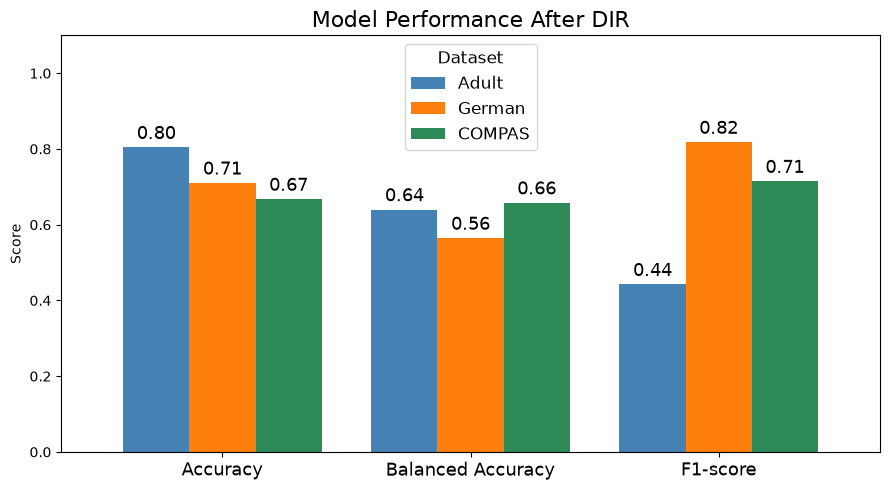

In [23]:
%matplotlib inline
ax = performance_table.set_index("Dataset").T.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8,
    color=["steelblue", "C1", "seagreen"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize = 13)

plt.title("Model Performance After DIR",fontsize = 16)
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0, fontsize=13)
plt.legend(title="Dataset", fontsize = 12, title_fontsize = 12)
plt.tight_layout()
plt.show()

## 6. Comparison of *before* versus *after*

In [24]:
comparison_table = pd.DataFrame({
    "Dataset": ["Adult", "German", "COMPAS"],
    "DP_Diff Before": [adult_dpdiff, german_dpdiff, compas_dpdiff],
    "DP_Diff After": [adult_dpdiff_after, german_dpdiff_after, compas_dpdiff_after],
    "DIR Before": [adult_dir, german_dir, compas_dir],
    "DIR After": [adult_dir_after, german_dir_after, compas_dir_after],
    "Consistency Before": [adult_consistency, german_consistency, compas_consistency],
    "Consistency After": [adult_consistency_after, german_consistency_after, compas_consistency_after]
})

comparison_table.round(3)

,Dataset,DP_Diff Before,DP_Diff After,DIR Before,DIR After,Consistency Before,Consistency After
0,Adult,0.196,0.030,0.358,0.751,0.831,0.970
1,German,0.075,0.010,0.897,0.989,0.747,0.926
2,COMPAS,0.140,0.275,0.773,0.641,0.621,0.984


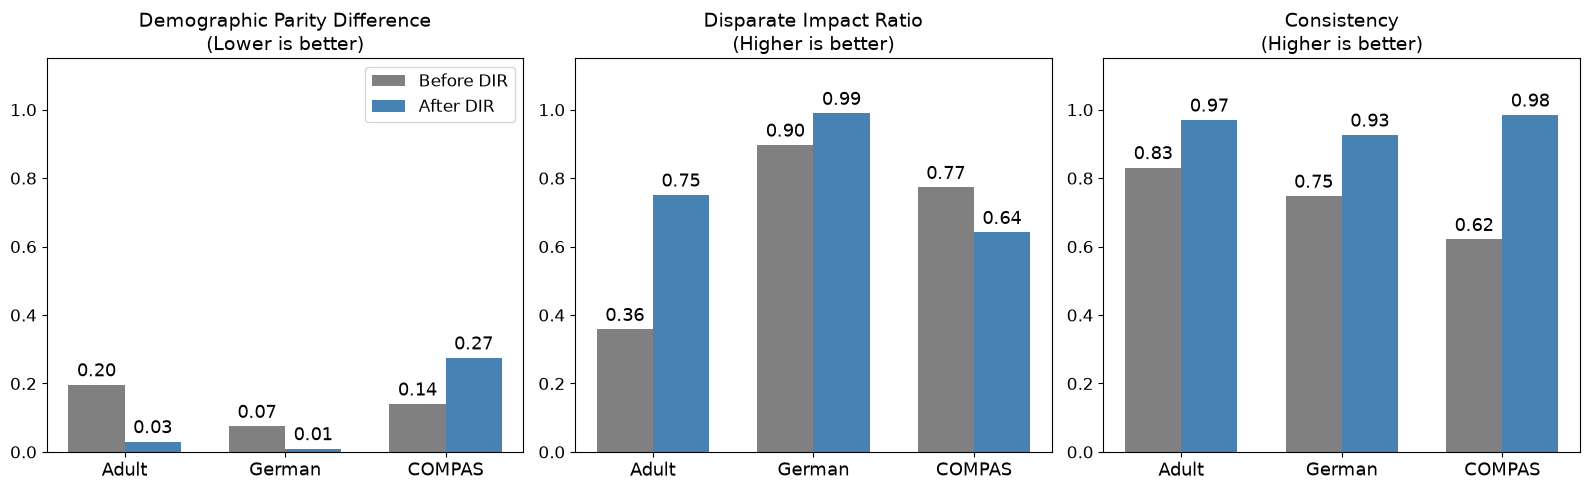

In [25]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

metrics = [
    ("DP_Diff Before", "DP_Diff After", "Demographic Parity Difference", "Lower is better"),
    ("DIR Before", "DIR After", "Disparate Impact Ratio", "Higher is better"),
    ("Consistency Before", "Consistency After", "Consistency", "Higher is better")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
x = np.arange(len(comparison_table))
width = 0.35

for ax, (before, after, title, subtitle) in zip(axes, metrics):

    bars1 = ax.bar(x - width/2, comparison_table[before], width,
                   label="Before DIR", color="grey")
    bars2 = ax.bar(x + width/2, comparison_table[after], width,
                   label="After DIR", color="steelblue")

    # Titles
    ax.set_title(f"{title}\n({subtitle})", fontsize=14)

    # X-axis
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_table["Dataset"], fontsize=13)

    # Y-axis
    ax.set_ylim(0, 1.15)
    ax.tick_params(axis="y", labelsize=12)

    # Numeric labels
    ax.bar_label(bars1, fmt="%.2f", padding=3, fontsize=13)
    ax.bar_label(bars2, fmt="%.2f", padding=3, fontsize=13)
    
axes[0].legend(fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()

#### Extra analysis on why bias has increased for Compas dataset
Firstly, I check which variables were changed by the algorithm and it's only the *number of priors*. When listing out all the uniques, I see that all the other attributes were binary, which suggests that this dataset is not the best candidate for this particular algorithm (binaries and many ordered categoricals have also remained unchanged in the other datasets, I'm just not showing it here to keep the report concise).

In [26]:
for feature in compas_train.drop(columns=["Two_yr_Recidivism", "race"]).columns:
    print(
        feature,
        (compas_train[feature].to_numpy() !=
         compas_train_repaired[feature].to_numpy()).sum()
    )

print("\nUnique values before and after DIR:")

for feature in compas_train.drop(columns=["Two_yr_Recidivism", "race"]).columns:
    print(feature)
    print("Before:", compas_train[feature].unique())
    print("After: ", compas_train_repaired[feature].unique())
    print()

Number_of_Priors 829
score_factor 0
Age_Above_FourtyFive 0
Age_Below_TwentyFive 0
Female 0
Misdemeanor 0

Unique values before and after DIR:
Number_of_Priors
Before: [0.15789474 0.         0.10526316 0.13157895 0.02631579 0.05263158
 0.07894737 0.68421053 0.36842105 0.42105263 0.52631579 0.65789474
 0.57894737 0.73684211 0.23684211 0.26315789 0.55263158 0.18421053
 0.31578947 0.28947368 0.21052632 0.44736842 0.60526316 0.34210526
 0.5        0.39473684 0.81578947 0.63157895 0.47368421 0.71052632
 0.94736842 0.97368421 1.         0.76315789 0.86842105]
After:  [0.13157895 0.         0.10526316 0.02631579 0.05263158 0.07894737
 0.68421053 0.34210526 0.39473684 0.15789474 0.47368421 0.60526316
 0.52631579 0.71052632 0.21052632 0.23684211 0.5        0.28947368
 0.36842105 0.18421053 0.55263158 0.26315789 0.73684211 0.31578947
 0.44736842 0.81578947 0.57894737 0.42105263 0.94736842 0.86842105]

score_factor
Before: [1. 0.]
After:  [1. 0.]

Age_Above_FourtyFive
Before: [1. 0.]
After:  [1. 0

#### However, it's still strange, that adjusting the one attribute reduced the performance. 

One plausible explanation could be that it's simply down to the classifier and not the preprocessing algorithm. To test this theory, I fit the same logistic regression to the unprocessed data and then compare the fairness measures. 

In [27]:
#training the model on the 'unrepaired' data
compas_X_train_original = compas_train.drop(
    columns=["Two_yr_Recidivism", "race"]
)
compas_y_train_original = compas_train["Two_yr_Recidivism"]

compas_model_original = LogisticRegression(max_iter=1000).fit(
    compas_X_train_original,
    compas_y_train_original
)

In [28]:
#making the predictions from this unrepaired data
compas_X_test_original = compas_test.drop(
    columns=["Two_yr_Recidivism", "race"]
)
compas_predictions_original = compas_model_original.predict(
    compas_X_test_original
)

# calculating the metrics
compas_dpdiff_before = -statistical_parity_difference(
    compas_predictions_original,
    prot_attr=compas_test["race"],
    priv_group=1,
    pos_label=1
)

compas_dir_before = disparate_impact_ratio(
    compas_predictions_original,
    prot_attr=compas_test["race"],
    priv_group=1,
    pos_label=1
)

In [29]:
compas_comparison = pd.DataFrame({
    "Model": ["Without DIR", "With DIR"],
    "DP_Diff (lower=better)": [compas_dpdiff_before, compas_dpdiff_after],
    "DIR (higher=better)": [compas_dir_before, compas_dir_after]
})

And we see that the fairness measures would have been even worse, albeit marginally, if the Disparate Impact Removal algorithm was not used. 

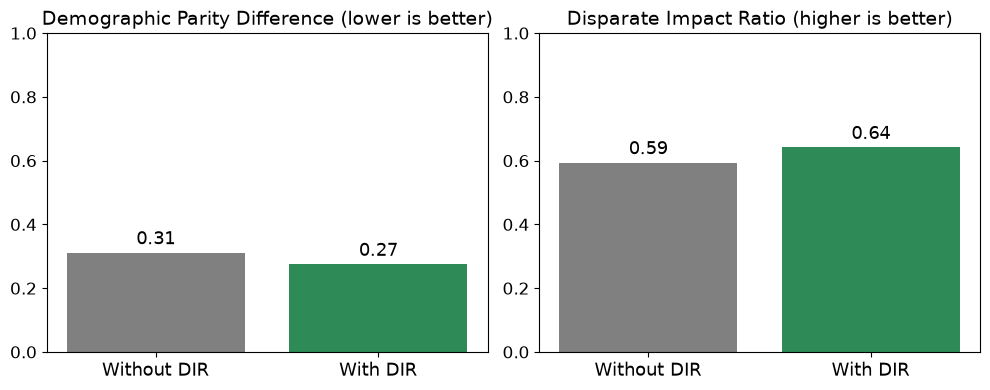

In [30]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

bars1 = axes[0].bar(
    compas_comparison["Model"],
    compas_comparison["DP_Diff (lower=better)"],
    color=["grey", "seagreen"]
)
axes[0].set_title("Demographic Parity Difference (lower is better)", fontsize=14)
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", labelsize=13)
axes[0].tick_params(axis="y", labelsize=12)
axes[0].bar_label(bars1, fmt="%.2f", padding=3, fontsize=13)

bars2 = axes[1].bar(
    compas_comparison["Model"],
    compas_comparison["DIR (higher=better)"],
    color=["grey", "seagreen"]
)
axes[1].set_title("Disparate Impact Ratio (higher is better)", fontsize=14)
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", labelsize=13)
axes[1].tick_params(axis="y", labelsize=12)
axes[1].bar_label(bars2, fmt="%.2f", padding=3, fontsize=13)

plt.tight_layout()
plt.show()